# Downstream analysis on Visium HD data of mouse small intestine

In [1]:
# Importing packages
import os
import metachat as mc
import scanpy as sc

import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
rcParams['pdf.fonttype'] = 42
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [2]:
# This notebook expects to run from the folder that contains the `datasets/`
# directory downloaded from Zenodo. If you started Jupyter somewhere else,
# point it here first, for example:
#     os.chdir("/path/to/the/folder/that/contains/datasets")


## Import MetaChat results 

In [3]:
adata = sc.read('datasets/mouse_small_intestine/metachat_result.h5ad')
adata.obs['Cluster'] = adata.obs['Cluster'].astype(str).astype('category')

In [4]:
adata

AnnData object with n_obs × n_vars = 3264 × 20143
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster', 'barrier_shapes', 'barrier', 'LRC_Blood_marker_Myh11', 'LRC_Blood_marker_Mgp', 'LRC_Blood_marker_Cldn5', 'LRC_Blood_avg_markers', 'LRC_Blood_marker_unfiltered', 'LRC_Blood_marker_filtered', 'visualize_LRC_marker', 'LRC_Blood_closepoint_cluster1'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'LRC_Blood_marker_filtered_colors', 'LRC_Blood_marker_unfiltered_colors', 'MetaChat-MetaChatDB-info', 'barrier_shapes', 'df_metasen_filtered', 'log1p', 'non_visible_pair', 'spatial', 'spatialdata_attrs', 'visualize_LRC_marker_colors'
    obsm: 'MetaChat-MetaChatDB-sum-receiver', 'MetaChat-MetaChatDB-sum-sender', 'spatial'
    obsp: 'LRC_shortest_Blood_dist80_cluster1', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Hcar2', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Slc16a7', 'MetaChat-MetaChatDB-receiver-HMDB0000011-Slc5a8', 'MetaChat-MetaChatDB-

## Compute group-level MCC of all pairs

To cluster MCC flow among all pairs, we need to compute group-level MCCs across all metabolite–sensor pairs.

In [5]:
# extract all_ms_pairs
df_metasen_filtered = adata.uns['df_metasen_filtered']
all_ms_pairs = (df_metasen_filtered['HMDB.ID'] + '-' + df_metasen_filtered['Sensor.Gene']).tolist()

In [6]:
mc.tl.communication_flow(adata = adata,
                         database_name = 'MetaChatDB',
                         sum_ms_pairs = all_ms_pairs,
                         k = 10)

Similarly, since the small intestine tissue is rolled, we used Napari to manually select a representative subregion for MCC flow clustering.
Here, we directly import the preprocessed results of this selected subregion for further analysis.

In [7]:
adata = sc.read_h5ad('datasets/mouse_small_intestine/metachat_result_flow_subset.h5ad')
adata_sub = adata[adata.obs['subset_direction_shapes'] == True]

In [8]:
adata

AnnData object with n_obs × n_vars = 3264 × 20143
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'Cluster', 'barrier_shapes', 'barrier', 'LRC_Blood_marker_Myh11', 'LRC_Blood_marker_Mgp', 'LRC_Blood_marker_Cldn5', 'LRC_Blood_avg_markers', 'LRC_Blood_marker_unfiltered', 'LRC_Blood_marker_filtered', 'visualize_LRC_marker', 'LRC_Blood_closepoint_cluster1', 'subset_direction_shapes'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'Cluster_colors', 'LRC_Blood_marker_filtered_colors', 'LRC_Blood_marker_unfiltered_colors', 'MetaChat-MetaChatDB-info', 'barrier_shapes', 'df_metasen_filtered', 'log1p', 'non_visible_pair', 'spatial', 'spatialdata_attrs', 'visualize_LRC_marker_colors'
    obsm: 'MetaChat-MetaChatDB-sum-receiver', 'MetaChat-MetaChatDB-sum-sender', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Hcar2', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Slc16a7', 'MetaChat-vf-MetaChatDB-receiver-HMDB0000011-Slc5a8', 'MetaChat-vf-MetaChatDB-receiver-HMDB000001

As an example, we show the flow of one metabolite-sensor pair, cholic acid
sensed through the bile-acid transporter `Slc10a2`. Any pair present in
`adata.uns['df_metasen_filtered']` can be used here.


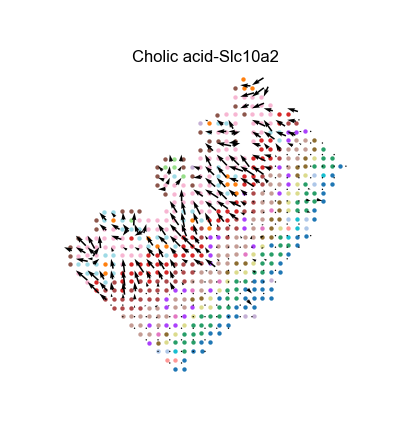

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(4,4))
pl = mc.pl.plot_communication_flow(
    adata = adata_sub, 
    database_name = 'MetaChatDB',
    ms_pair_name = 'HMDB0000619-Slc10a2',   # Cholic acid - Slc10a2
    plot_method = 'grid',
    background = 'group',
    group_name = 'Cluster',
    summary = 'receiver',
    ndsize = 10,
    largest_arrow = 0.05,
    normalize_v_quantile = 0.995,
    grid_density = 0.5,
    title = 'Cholic acid-Slc10a2',
    ax = ax)

## Classify MCC flow directions

The small intestine is rolled, so a flow direction is only meaningful relative to
the local tissue layers. We therefore (1) build a local anatomical axis that points
from the muscularis towards the epithelium, (2) describe the flow field of every
metabolite–sensor pair with a few interpretable features measured along that axis,
and (3) assign each pair to a class with two explicit thresholds. Here we analyse
the `sender` fields; set `summary = 'receiver'` to analyse the receiver side instead.

### Anatomical axis

`s(x)` is a smoothed epithelial-minus-muscularis marker score. Its local gradient
gives a unit vector `u(x)` that points from muscularis to epithelium and follows the
curvature of the tissue. `s(x)` is also used to cut the tissue into 5 layers with
equal numbers of spots.

In [10]:
xy = np.asarray(adata_sub.obsm['spatial'], float)
n_spot = adata_sub.n_obs

epi_genes = [g for g in ['Epcam', 'Vil1', 'Krt8', 'Krt18', 'Alpi'] if g in adata_sub.var_names]
mus_genes = [g for g in ['Myh11', 'Acta2', 'Des', 'Tagln'] if g in adata_sub.var_names]

def _score(genes):
    X = adata_sub[:, genes].X
    X = np.asarray(X.todense()) if hasattr(X, 'todense') else np.asarray(X)
    return X.mean(1)

K_NN = 20
nn = NearestNeighbors(n_neighbors=K_NN).fit(xy)
dist, idx = nn.kneighbors(xy)

s = (_score(epi_genes) - _score(mus_genes))[idx].mean(1)
s = (s - s.mean()) / s.std()

# local weighted least-squares gradient of s
U = np.zeros((n_spot, 2))
for i in range(n_spot):
    j = idx[i]
    A = np.c_[xy[j] - xy[i], np.ones(K_NN)]
    w = np.exp(-(dist[i] / (dist[i].max() + 1e-9)) ** 2)
    coef, *_ = np.linalg.lstsq(A * w[:, None], (s[j] - s[i]) * w, rcond=None)
    U[i] = coef[:2]

U_norm = np.linalg.norm(U, axis=1)
Uhat = U / np.maximum(U_norm, 1e-12)[:, None]
good_axis = U_norm > np.percentile(U_norm, 10)

N_BIN = 5
q = np.quantile(s, np.linspace(0, 1, N_BIN + 1)); q[0] -= 1e-6; q[-1] += 1e-6
depth_bin = np.digitize(s, q[1:-1])
bin_names = ['muscularis', 'musc/submuc', 'middle', 'sub-epi', 'epithelium']
print('well-defined axis at', good_axis.sum(), '/', n_spot, 'spots')
print(dict(zip(bin_names, np.bincount(depth_bin))))

well-defined axis at 477 / 530 spots
{'muscularis': 106, 'musc/submuc': 106, 'middle': 106, 'sub-epi': 106, 'epithelium': 106}


### Flow features

For every pair with a non-zero flow in at least 20 spots we compute:

- `axial`: magnitude-weighted projection of the flow on `u` (+1 = muscularis → epithelium, −1 = epithelium → muscularis);
- `tang`: the component perpendicular to `u`;
- `coh`: global directional coherence of the field;
- `mass_bin*`: fraction of the flow magnitude in each layer, and `axial_bin*`: mean axial projection within each layer;
- `mass_center`: centre of the layer profile (0 = muscularis, 4 = epithelium).

`total-total` is excluded because it is MetaChat's aggregate field over all pairs, not a single metabolite–sensor pair.

In [11]:
summary = 'sender'
MIN_SPOTS = 20
EXCLUDE = {'total-total'}

feat_cols = ['axial', 'tang', 'coh'] + [f'mass_bin{b}' for b in range(N_BIN)] \
                                     + [f'axial_bin{b}' for b in range(N_BIN)]

prefix = f'MetaChat-vf-MetaChatDB-{summary}-'
keys = [k for k in adata_sub.obsm if k.startswith(prefix) and k[len(prefix):] not in EXCLUDE]
names = [k[len(prefix):] for k in keys]
V_all = np.stack([np.asarray(adata_sub.obsm[k], float) for k in keys], 0)
mag = np.linalg.norm(V_all, axis=2)
n_nz = (mag > 0).sum(1)
keep = np.where(n_nz >= MIN_SPOTS)[0]
print(f'{len(names)} pairs -> {len(keep)} with >= {MIN_SPOTS} nonzero spots')

rows = []
for p in keep:
    V = V_all[p]
    w = mag[p].copy(); w[~good_axis] = 0.0
    if w.sum() <= 0:
        continue
    pw = w / w.sum()
    Vh = V / np.maximum(mag[p], 1e-12)[:, None]
    ax_proj = (Vh * Uhat).sum(1)
    tan_proj = np.abs(Vh[:, 0] * Uhat[:, 1] - Vh[:, 1] * Uhat[:, 0])
    prof = np.array([pw[depth_bin == b].sum() for b in range(N_BIN)])
    axb = np.array([(pw[depth_bin == b] * ax_proj[depth_bin == b]).sum()
                    / max(prof[b], 1e-12) for b in range(N_BIN)])
    rows.append(dict(pair=names[p],
                     axial=float((pw * ax_proj).sum()),
                     tang=float((pw * tan_proj).sum()),
                     coh=float(np.linalg.norm((w[:, None] * Vh).sum(0)) / w.sum()),
                     **{f'mass_bin{b}': prof[b] for b in range(N_BIN)},
                     **{f'axial_bin{b}': axb[b] for b in range(N_BIN)},
                     n_nz=int(n_nz[p])))
df_flow = pd.DataFrame(rows).set_index('pair')
df_flow['mass_center'] = (df_flow[[f'mass_bin{b}' for b in range(N_BIN)]].values * np.arange(N_BIN)).sum(1)
df_flow.head()

1065 pairs -> 572 with >= 20 nonzero spots


,axial,tang,coh,mass_bin0,mass_bin1,mass_bin2,mass_bin3,mass_bin4,axial_bin0,axial_bin1,axial_bin2,axial_bin3,axial_bin4,n_nz,mass_center
pair,,,,,,,,,,,,,,,
HMDB0000012-Slc29a2,0.044683,0.772545,0.234956,0.607415,0.325703,0.058803,0.008080,0.000000,0.246387,-0.325041,0.065249,-0.364668,0.000000,117,0.467547
HMDB0000014-Slc29a2,0.125327,0.769864,0.238451,0.623915,0.280642,0.052515,0.042927,0.000000,0.355561,-0.240422,-0.076545,-0.582862,0.000000,125,0.514454
HMDB0000033-Slc16a13,0.324140,0.483787,0.378011,0.495943,0.346981,0.089823,0.036446,0.030806,0.789235,0.037710,-0.583688,-0.439649,-0.386536,273,0.759192
HMDB0000034-Slc28a3,-0.022458,0.539451,0.094479,0.169824,0.106711,0.268846,0.350596,0.104022,0.873941,0.805115,0.032224,-0.557690,-0.672245,165,2.112280
HMDB0000034-Slc29a2,0.095783,0.787649,0.254724,0.643363,0.237117,0.028434,0.091086,0.000000,0.344710,-0.337087,-0.668449,-0.297026,0.000000,83,0.567244


### Rule-based classes

Each pair is classified by two thresholds on interpretable quantities:

- **direction**, from `axial`: `>= +0.25` → `musc->epi`; `<= -0.25` → `epi->musc`; otherwise `tangential/mixed`;
- **location**, from `mass_center`: `<= 1.4` → `muscularis`; `>= 2.6` → `epithelial`; otherwise `mid`.

This gives 3 × 3 = 9 named classes.

In [12]:
AXIAL_HI, AXIAL_LO = 0.25, -0.25
LOC_EPI, LOC_MUS = 2.6, 1.4

DIRS = ['musc->epi', 'tangential/mixed', 'epi->musc']
LOCS = ['muscularis', 'mid', 'epithelial']
CLASS_ORDER = [f'{d} @ {l}' for d in DIRS for l in LOCS]

def rule_label(r):
    d = 'musc->epi' if r['axial'] >= AXIAL_HI else ('epi->musc' if r['axial'] <= AXIAL_LO
                                                    else 'tangential/mixed')
    l = 'epithelial' if r['mass_center'] >= LOC_EPI else ('muscularis' if r['mass_center'] <= LOC_MUS
                                                          else 'mid')
    return f'{d} @ {l}'

df_flow['rule class'] = pd.Categorical(df_flow.apply(rule_label, axis=1),
                                       categories=CLASS_ORDER, ordered=True)
df_flow['rule class'].value_counts().reindex(CLASS_ORDER).to_frame('# MS pairs')

,# MS pairs
rule class,
musc->epi @ muscularis,123
musc->epi @ mid,80
musc->epi @ epithelial,35
tangential/mixed @ muscularis,142
tangential/mixed @ mid,118
tangential/mixed @ epithelial,28
epi->musc @ muscularis,38
epi->musc @ mid,4
epi->musc @ epithelial,4


### Flow similarity ordered by class

Finally, we compute the cosine similarity between pairs in the standardised feature
space and draw it with the pairs ordered by class. White boxes mark the classes. The
colour scale is fixed to [−1, 1].

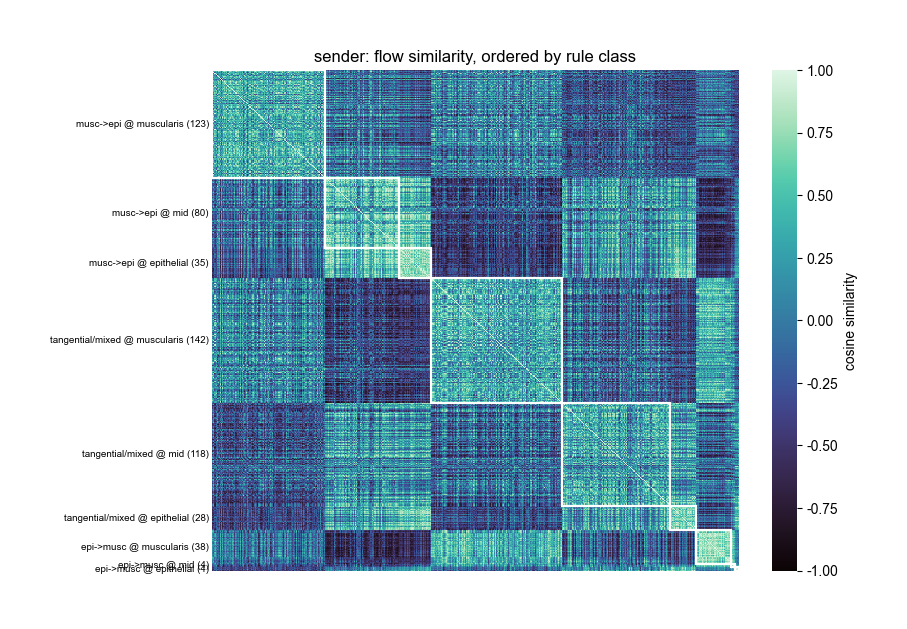

In [13]:
X = StandardScaler().fit_transform(df_flow[feat_cols].values)
Xn = X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)
S = Xn @ Xn.T

lab = df_flow['rule class'].values
order = np.argsort(lab.codes, kind='stable')

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(S[order][:, order], cmap='mako', vmin=-1, vmax=1, ax=ax,
            xticklabels=False, yticklabels=False,
            cbar_kws={'label': 'cosine similarity'})
b = 0
for c in CLASS_ORDER:
    k = int((lab == c).sum())
    if k == 0:
        continue
    ax.add_patch(plt.Rectangle((b, b), k, k, fill=False, ec='w', lw=1.6))
    ax.text(-3, b + k / 2, f'{c} ({k})', ha='right', va='center', fontsize=7)
    b += k
ax.set_title(f'{summary}: flow similarity, ordered by rule class')
plt.show()